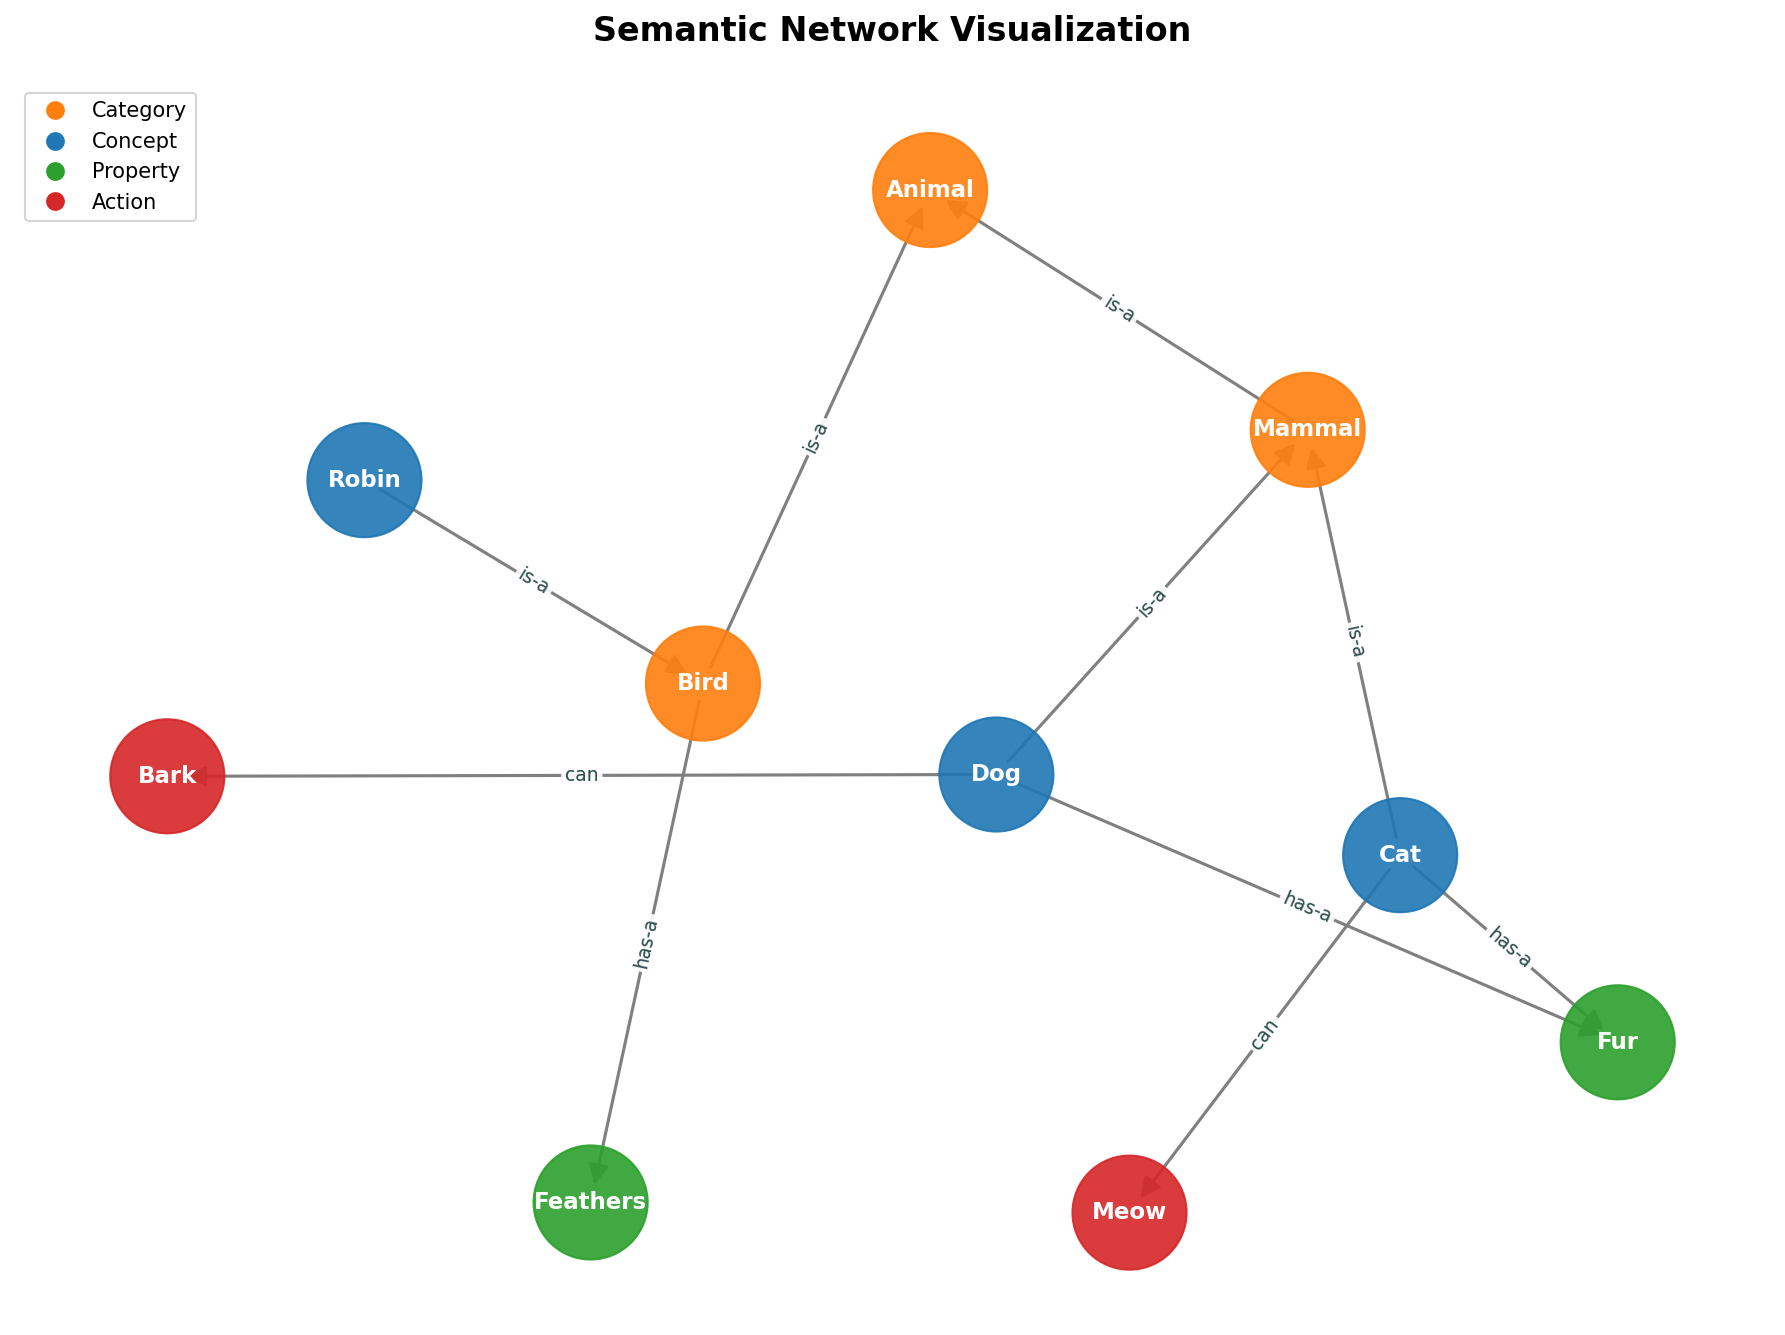

In [1]:
!pip install -q networkx matplotlib

import networkx as nx
import matplotlib.pyplot as plt

%matplotlib inline

G = nx.DiGraph()

nodes_data = [
    ("Animal", {"type": "Category"}),
    ("Mammal", {"type": "Category"}),
    ("Bird", {"type": "Category"}),
    ("Dog", {"type": "Concept"}),
    ("Cat", {"type": "Concept"}),
    ("Robin", {"type": "Concept"}),
    ("Fur", {"type": "Property"}),
    ("Feathers", {"type": "Property"}),
    ("Bark", {"type": "Action"}),
    ("Meow", {"type": "Action"}),
]
G.add_nodes_from(nodes_data)

edges_data = [
    ("Mammal", "Animal", {"relation": "is-a"}),
    ("Bird", "Animal", {"relation": "is-a"}),
    ("Dog", "Mammal", {"relation": "is-a"}),
    ("Cat", "Mammal", {"relation": "is-a"}),
    ("Robin", "Bird", {"relation": "is-a"}),
    ("Dog", "Fur", {"relation": "has-a"}),
    ("Cat", "Fur", {"relation": "has-a"}),
    ("Bird", "Feathers", {"relation": "has-a"}),
    ("Dog", "Bark", {"relation": "can"}),
    ("Cat", "Meow", {"relation": "can"}),
]

for u, v, data in edges_data:
    G.add_edge(u, v, relation=data["relation"])
plt.figure(figsize=(12, 9), dpi=150)

pos = nx.spring_layout(G, seed=42, k=0.9)

color_map = {
    "Category": "#ff7f0e",
    "Concept": "#1f77b4",
    "Property": "#2ca02c",
    "Action": "#d62728"
}
node_colors = [color_map.get(data.get("type"), "#gray") for _, data in G.nodes(data=True)]

nx.draw_networkx_nodes(
    G, pos, 
    node_color=node_colors, 
    node_size=3000, 
    alpha=0.9
)

nx.draw_networkx_edges(
    G, pos, 
    edge_color="gray", 
    arrows=True, 
    arrowstyle="-|>", 
    arrowsize=20, 
    width=1.5
)

nx.draw_networkx_labels(
    G, pos, 
    font_size=11, 
    font_weight="bold", 
    font_color="white"
)

edge_labels = nx.get_edge_attributes(G, "relation")
nx.draw_networkx_edge_labels(
    G, pos, 
    edge_labels=edge_labels, 
    font_size=9, 
    font_color="darkslategray",
    bbox=dict(boxstyle="round,pad=0.2", edgecolor="none", facecolor="white", alpha=0.7)
)
edge_labels = nx.get_edge_attributes(G, "relation")
nx.draw_networkx_edge_labels(
    G, pos, 
    edge_labels=edge_labels, 
    font_size=9, 
    font_color="darkslategray",
    bbox=dict(boxstyle="round,pad=0.2", edgecolor="none", facecolor="white", alpha=0.7)
)

from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Category', markerfacecolor='#ff7f0e', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Concept', markerfacecolor='#1f77b4', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Property', markerfacecolor='#2ca02c', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Action', markerfacecolor='#d62728', markersize=10),
]
plt.legend(handles=legend_elements, loc="upper left", fontsize=10, frameon=True)

plt.title("Semantic Network Visualization", fontsize=16, fontweight="bold", pad=20)
plt.axis("off")
plt.tight_layout()

plt.show()